# 2. Phân tích khám phá dữ liệu (EDA)
Tìm hiểu dữ liệu gốc trước khi tiền xử lý: phân bố nhãn, chất lượng dữ liệu, độ dài bài, chủ đề,
dấu hiệu nguồn tin và các từ phổ biến của mỗi lớp. Các phát hiện ở đây quyết định cách làm ở notebook 3.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

RAW_DIR = Path("data/raw")
COLORS = {"Fake": "#eb6834", "True": "#2a78d6"}

df = pd.concat([pd.read_csv(RAW_DIR / "Fake.csv").assign(label="Fake"),
                pd.read_csv(RAW_DIR / "True.csv").assign(label="True")], ignore_index=True)
df[["title", "text"]] = df[["title", "text"]].fillna("")
print(f"{len(df):,} bài × {df.shape[1]} cột")
df.head()

44,898 bài × 5 cột


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",Fake
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",Fake
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",Fake
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",Fake
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",Fake


### Phân bố nhãn

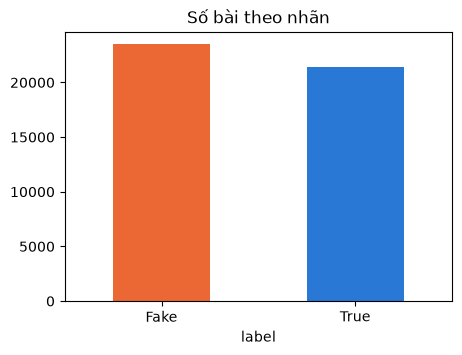

,Số bài,%
label,,
Fake,23481,52.3
True,21417,47.7


In [2]:
counts = df["label"].value_counts()
counts.plot.bar(color=[COLORS[k] for k in counts.index], rot=0, title="Số bài theo nhãn", figsize=(5, 3.5))
plt.show()
pd.DataFrame({"Số bài": counts, "%": (counts / len(df) * 100).round(1)})

### Chất lượng dữ liệu: bài rỗng và trùng lặp

In [3]:
pd.DataFrame({
    "Text rỗng": df["text"].str.strip().eq("").groupby(df["label"]).sum(),
    "Trùng title + text": df.duplicated(["title", "text"]).groupby(df["label"]).sum(),
    "Trùng text (không tính rỗng)": (df["text"].duplicated() & df["text"].str.strip().ne("")).groupby(df["label"]).sum(),
})

,Text rỗng,Trùng title + text,Trùng text (không tính rỗng)
label,,,
Fake,630,5573,5398
True,1,220,225


### Độ dài bài báo

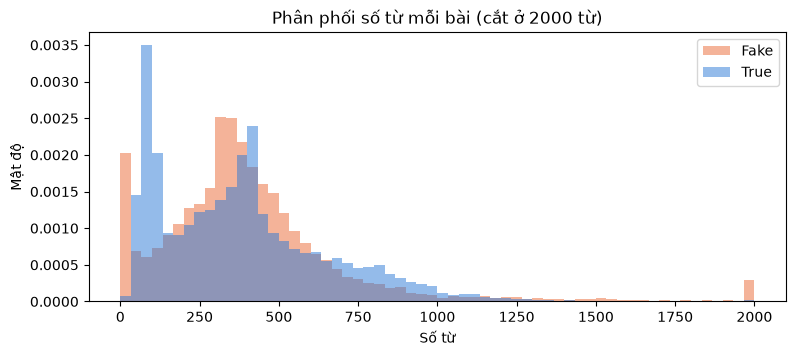

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Fake,23481.0,423.0,408.0,0.0,240.0,363.0,506.0,8135.0
True,21417.0,386.0,274.0,0.0,148.0,359.0,525.0,5172.0


In [4]:
df["so_tu"] = df["text"].str.split().str.len()

fig, ax = plt.subplots(figsize=(9, 3.5))
for label, g in df.groupby("label"):
    g["so_tu"].clip(upper=2000).plot.hist(bins=60, density=True, alpha=0.5, color=COLORS[label], label=label, ax=ax)
ax.set(title="Phân phối số từ mỗi bài (cắt ở 2000 từ)", xlabel="Số từ", ylabel="Mật độ")
ax.legend()
plt.show()
df.groupby("label")["so_tu"].describe().round(0)

### Chủ đề (`subject`)

In [5]:
pd.crosstab(df["subject"], df["label"])

label,Fake,True
subject,,
Government News,1570,0
Middle-east,778,0
News,9050,0
US_News,783,0
left-news,4459,0
politics,6841,0
politicsNews,0,11272
worldnews,0,10145


### Dấu hiệu nguồn tin / định dạng
Tỷ lệ % bài trong mỗi lớp có chứa mẫu văn bản đặc trưng của nguồn đăng.

In [6]:
MARKERS = {"(Reuters)": r"\(reuters\)", "featured image": r"featured image",
           "pic.twitter.com": r"pic\.twitter\.com", "đường link http(s)": r"https?://"}
pd.DataFrame({name: df["text"].str.contains(p, case=False).groupby(df["label"]).mean() * 100
              for name, p in MARKERS.items()}).T.round(1)

label,Fake,True
(Reuters),0.0,99.2
featured image,34.8,0.0
pic.twitter.com,14.8,0.0
đường link http(s),14.0,0.0


### Từ phổ biến nhất của mỗi lớp (văn bản gốc, đã bỏ stop-word)

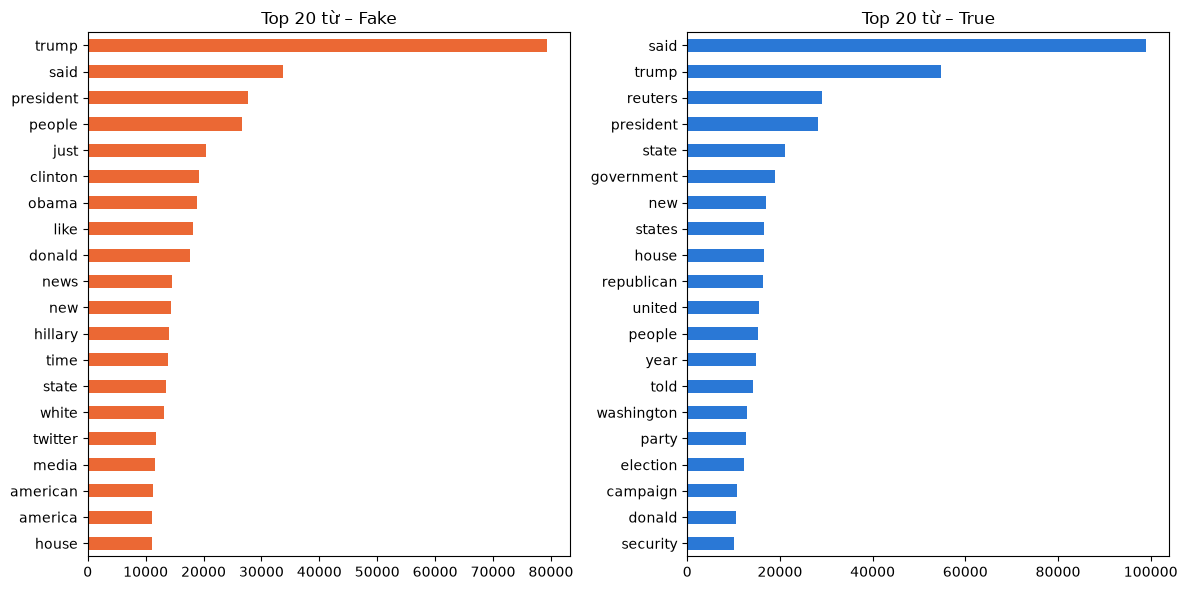

In [7]:
cv = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", min_df=5)
X = cv.fit_transform(df["text"])
words = cv.get_feature_names_out()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, label in zip(axes, ["Fake", "True"]):
    freq = pd.Series(np.asarray(X[(df["label"] == label).to_numpy()].sum(axis=0)).ravel(), index=words)
    freq.nlargest(20)[::-1].plot.barh(ax=ax, color=COLORS[label], title=f"Top 20 từ – {label}")
plt.tight_layout()
plt.show()

### Kết luận EDA → hướng xử lý ở các notebook sau
- **Nhãn gần cân bằng** (Fake 52,3% / True 47,7%) → không cần xử lý mất cân bằng, chỉ cần chia train/test có `stratify`.
- **Dữ liệu bẩn**: 631 bài có text rỗng (gần như toàn bộ là Fake) và hơn 5 000 bài trùng lặp → loại bỏ sau tiền xử lý (notebook 3).
- **`subject` tách biệt hoàn toàn hai lớp** (không chủ đề nào có cả Fake lẫn True) → **không dùng làm đặc trưng**, nếu dùng sẽ là rò rỉ nhãn.
- **Dấu hiệu nguồn tin**: 99,2% bài True có `(Reuters)`, còn *featured image*, link twitter chỉ xuất hiện ở Fake → xóa dấu hiệu `Reuters` khi làm sạch, để mô hình không học "nguồn đăng" thay cho nội dung.
- **Độ dài** hai lớp có trung vị tương đương (~360 từ), Fake phân tán hơn → độ dài không phải đặc trưng phân biệt mạnh.